<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet9/Tugas%201%20(JS9).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np

# Load dataset voice
df = pd.read_csv('voice.csv')
df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Memisahkan Fitur (X) dan Label (y)
# Label berada di kolom terakhir ('label') dengan nilai 'male' / 'female'
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Encoding label: male -> 1, female -> 0 (atau biarkan string karena scikit-learn bisa handle string label)
# Kita bisa mapping atau biarkan langsung, di sini kita gunakan langsung atau map ke integer:
y = y.map({'male': 1, 'female': 0})

# 2. Split Data (Training 70%, Testing 30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Standardisasi Fitur (Sangat penting untuk kNN agar skala fitur seimbang)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Inisialisasi dan Latih Model kNN (misal K=3)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# 5. Evaluasi Model
y_pred = knn.predict(X_test)
print("Akurasi kNN (k=3):", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Akurasi kNN (k=3): 0.9768664563617245

Confusion Matrix:
 [[440  12]
 [ 10 489]]

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.97      0.98       452
           1       0.98      0.98      0.98       499

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951




2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

In [15]:
# ==========================================
# 1. Menampilkan Semua Fitur yang Ada
# ==========================================
print("Daftar seluruh fitur pada dataset voice.csv:")
all_features = X.columns.tolist()
for idx, feature in enumerate(all_features, 1):
    print(f"{idx}. {feature}")

print("\n" + "="*50 + "\n")

# ==========================================
# 2. Menyeleksi & Menentukan Fitur Terbaik
# ==========================================
from sklearn.feature_selection import SelectKBest, f_classif

# Menggunakan SelectKBest untuk mengukur skor signifikansi setiap fitur terhadap label
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_train, y_train)

# Buat DataFrame skor fitur
feature_scores = pd.DataFrame({
    'Fitur': X.columns,
    'Skor F-Value': selector.scores_
}).sort_values(by='Skor F-Value', ascending=False)

print("Peringkat Fitur berdasarkan Signifikansi (Skor F-Value):")
print(feature_scores.to_string(index=False))

# Memilih 10 Fitur Terbaik
k_optimal = 10
best_features = feature_scores.head(k_optimal)['Fitur'].tolist()

print(f"\n---> {k_optimal} Fitur yang Paling Optimal Digunakan:")
for f in best_features:
    print(f"- {f}")

selected_indices = [X.columns.get_loc(f) for f in best_features]

X_train_selected = X_train[:, selected_indices]
X_test_selected = X_test[:, selected_indices]

Daftar seluruh fitur pada dataset voice.csv:
1. meanfreq
2. sd
3. median
4. Q25
5. Q75
6. IQR
7. skew
8. kurt
9. sp.ent
10. sfm
11. mode
12. centroid
13. meanfun
14. minfun
15. maxfun
16. meandom
17. mindom
18. maxdom
19. dfrange
20. modindx


Peringkat Fitur berdasarkan Signifikansi (Skor F-Value):
   Fitur  Skor F-Value
 meanfun   5029.522726
     IQR   1327.392845
     Q25    744.373408
  sp.ent    686.673230
      sd    631.538022
     sfm    305.745649
centroid    261.915407
meanfreq    261.915407
  median    172.938508
 meandom     87.002711
  maxdom     82.590930
  mindom     82.340156
 dfrange     79.599270
  maxfun     68.897484
    mode     56.349871
  minfun     33.107663
    kurt     16.317164
     Q75     11.668036
    skew      2.055640
 modindx      1.023812

---> 10 Fitur yang Paling Optimal Digunakan:
- meanfun
- IQR
- Q25
- sp.ent
- sd
- sfm
- centroid
- meanfreq
- median
- meandom



3. Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.

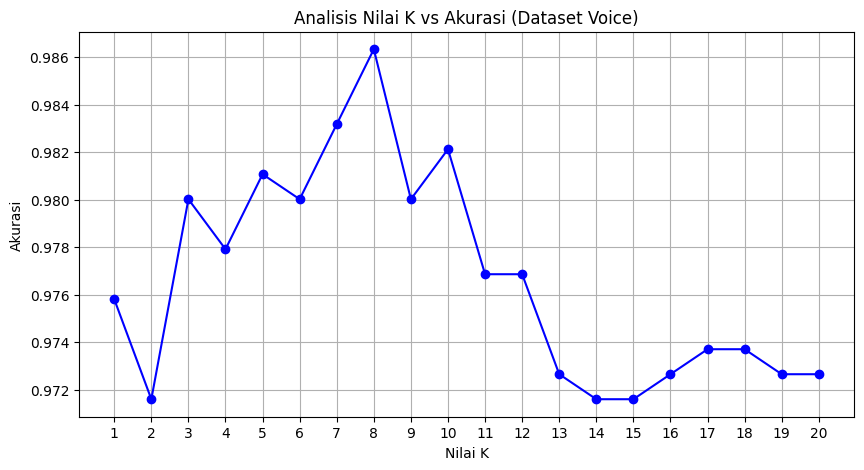

Nilai K terbaik adalah 8 dengan akurasi tertinggi sebesar: 0.9863


In [13]:
import matplotlib.pyplot as plt

acc_list = []
k_range = range(1, 21)

for k in k_range:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_train_selected, y_train)
    y_p = knn_k.predict(X_test_selected)
    acc_list.append(accuracy_score(y_test, y_p))

# Plot Grafik Analisis Nilai K vs Akurasi
plt.figure(figsize=(10, 5))
plt.plot(k_range, acc_list, marker='o', linestyle='-', color='b')
plt.title('Analisis Nilai K vs Akurasi (Dataset Voice)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Menampilkan nilai K dengan akurasi tertinggi
best_k = k_range[np.argmax(acc_list)]
print(f"Nilai K terbaik adalah {best_k} dengan akurasi tertinggi sebesar: {max(acc_list):.4f}")